# Process Fluvius Digital-Meter Solar Household Dataset

## Purpose
This notebook builds a half-hourly aggregate net load dataset for Belgium from the Fluvius open data release of digital electricity meter readings, so that the journal article can compare models on a European dataset. Fluvius publishes quarter-hourly offtake and injection for 2,400 anonymised residential meters for calendar 2024, split into eight consumption profiles. Only the profile of households with solar panels and neither a heat pump nor an electric vehicle (`enkel_ZP`, 300 meters) is used. The meters are summed into one aggregate and resampled to 30 minutes, mirroring the Ausgrid Solar Home Dataset (ASHD) recipe in `01 Process ASHD Data`.

Source: Fluvius Open Data, *Verbruiksprofielen digitale elektriciteitsmeters: kwartierwaarden voor een volledig jaar* (dataset `1_50`), https://opendata.fluvius.be, last updated by Fluvius on 2025-09-29. Reuse, redistribution and commercial use are permitted under the Fluvius open data licence provided Fluvius and the date of the last update are named. Weather: Open-Meteo historical weather API (CC BY 4.0) for Brussels-Uccle.

## Inputs
- `ZIP_PATH / MEMBER_NAME`: quarter-hourly `Volume_Afname_KWh` and `Volume_Injectie_KWh` per meter, timestamps on the CET/CEST wall clock
- `LEGEND_PATH`: the Fluvius legend workbook describing the columns (read for the record, not parsed)
- `OPEN_METEO_PATH`: hourly temperature, relative humidity and wind speed at Brussels-Uccle in UTC, fetched from `OPEN_METEO_URL` when absent

`ZIP_PATH` is `<PYNNLF_RAW_DATA_DIR>/1. raw/Fluvius/P6269_1_50_DMK_Sample_Elek_2024_Deel_1.zip`, attachment `Deel_1` of the dataset page.

## Run Flow
1. Setup
2. Read the solar-household profile
3. Move the wall clock to Central European Time
4. Export `ds39`: Fluvius aggregate without weather
5. Add Brussels-Uccle weather for `ds40`
6. Final validation

## Outputs
- `data/ds39_fluvius_pv_30min.csv` and a copy in `publication/journal_article_1/data/`
- `data/ds40_fluvius_pv_30min_with_weather.csv` and a copy in `publication/journal_article_1/data/`


## 1. Setup

Define the raw-data locations, the expected half-hourly index for 2024 in Central European Time, and the output files. Paths are resolved from the repository root so the notebook runs from the root or from this folder. Printed paths are shown relative to the repository root.

In [1]:
import json
import os
import shutil
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_repo_root(start=None):
    """Find the PyNNLF repository root from the current working directory."""
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / ".git").exists() and (candidate / "data").exists():
            return candidate
    raise FileNotFoundError("Could not locate the PyNNLF repository root.")


def raw_data_root():
    """Locate the local source data tree, which is not distributed with this repository.

    Set the PYNNLF_RAW_DATA_DIR environment variable to the directory holding the
    "1. raw" folder before running this notebook.

    Returns:
        Path: root of the local source data tree.
    """
    root = os.environ.get("PYNNLF_RAW_DATA_DIR")
    if not root:
        raise RuntimeError(
            "PYNNLF_RAW_DATA_DIR is not set. Point it at your local source data "
            "directory; see the Data section of the repository README."
        )
    return Path(root)


REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT / "data"
PUBLICATION_DATA_DIR = REPO_ROOT / "publication" / "journal_article_1" / "data"

RAW_DATA_ROOT = raw_data_root()
RAW_FLUVIUS_DIR = RAW_DATA_ROOT / "1. raw" / "Fluvius"
ZIP_PATH = RAW_FLUVIUS_DIR / "P6269_1_50_DMK_Sample_Elek_2024_Deel_1.zip"
MEMBER_NAME = "P6269_Open_Data_enkel_ZP.csv"  # solar panels, no heat pump, no electric vehicle
LEGEND_PATH = RAW_FLUVIUS_DIR / "1_50_Aanleveirng_DMK_Elek_Fluvius_Legende_25200929.xlsx"

OPEN_METEO_PATH = RAW_DATA_ROOT / "1. raw" / "Open-Meteo" / "uccle_2024_hourly.json"
OPEN_METEO_URL = (
    "https://archive-api.open-meteo.com/v1/archive"
    "?latitude=50.80&longitude=4.36&start_date=2023-12-31&end_date=2024-12-31"
    "&hourly=temperature_2m,relative_humidity_2m,wind_speed_10m&timezone=UTC"
)

# Central European Time (UTC+1) all year, so the index has no gap or repeat.
LOCAL_ZONE = "Europe/Brussels"
STANDARD_ZONE = "Etc/GMT-1"
START = pd.Timestamp("2024-01-01 00:00:00")
END = pd.Timestamp("2024-12-31 23:30:00")
EXPECTED_INDEX = pd.date_range(START, END, freq="30min", name="datetime")
EXPECTED_ROWS = len(EXPECTED_INDEX)
QUARTER_HOUR_INDEX = pd.date_range(START, END + pd.Timedelta(minutes=15), freq="15min", name="datetime")
EXPECTED_METERS = 300

WEATHER_COLUMNS = [
    "air_temperature_in_degrees_c",
    "relative_humidity_in_percentage",
    "wind_speed_in_km_h",
]

DS39_PATH = DATA_DIR / "ds39_fluvius_pv_30min.csv"
DS40_PATH = DATA_DIR / "ds40_fluvius_pv_30min_with_weather.csv"

for required in [ZIP_PATH, LEGEND_PATH]:
    if not required.exists():
        raise FileNotFoundError(f"Missing raw Fluvius file: {required.relative_to(RAW_DATA_ROOT)}")

print(f"Expected rows: {EXPECTED_ROWS:,} half-hourly from {START} to {END} (CET)")


Expected rows: 17,568 half-hourly from 2024-01-01 00:00:00 to 2024-12-31 23:30:00 (CET)


## 2. Read the solar-household profile

The profile file is read straight from the ZIP archive with only the columns this notebook needs. Every meter in the release is residential for the whole year and carries all quarter-hours (the legend states that unused meters were excluded), which is checked here before anything is aggregated.

In [2]:
USE_COLUMNS = [
    "EAN_ID",
    "Datum_Startuur",
    "Volume_Afname_KWh",
    "Volume_Injectie_KWh",
    "Warmtepomp_Indicator",
    "Elektrisch_Voertuig_Indicator",
    "PV_Installatie_Indicator",
    "Contract_Categorie",
]

with zipfile.ZipFile(ZIP_PATH) as archive:
    with archive.open(MEMBER_NAME) as member:
        readings = pd.read_csv(
            member,
            usecols=USE_COLUMNS,
            dtype={"EAN_ID": "int32", "Volume_Afname_KWh": "float64", "Volume_Injectie_KWh": "float64"},
        )

meters = readings["EAN_ID"].nunique()
rows_per_meter = readings.groupby("EAN_ID").size()
indicator_sets = readings[["Warmtepomp_Indicator", "Elektrisch_Voertuig_Indicator", "PV_Installatie_Indicator"]].drop_duplicates()

if meters != EXPECTED_METERS:
    raise AssertionError(f"Expected {EXPECTED_METERS} meters, found {meters}")
if not rows_per_meter.eq(len(QUARTER_HOUR_INDEX)).all():
    raise AssertionError("Every meter must carry one reading per quarter-hour of 2024")
if not readings["Contract_Categorie"].eq("Residentieel").all():
    raise AssertionError("Every meter must be residential")
if indicator_sets.values.tolist() != [[0, 0, 1]]:
    raise AssertionError(f"Unexpected indicator combinations: {indicator_sets.values.tolist()}")
if readings[["Volume_Afname_KWh", "Volume_Injectie_KWh"]].isna().any().any():
    raise AssertionError("Readings contain missing volumes")

print(f"Read {len(readings):,} quarter-hour readings for {meters} meters from {MEMBER_NAME}")
print(f"Mean offtake {readings['Volume_Afname_KWh'].mean():.4f} kWh and injection {readings['Volume_Injectie_KWh'].mean():.4f} kWh per quarter-hour per meter")
display(readings.head())


Read 10,540,800 quarter-hour readings for 300 meters from P6269_Open_Data_enkel_ZP.csv


Mean offtake 0.0567 kWh and injection 0.0654 kWh per quarter-hour per meter


,EAN_ID,Datum_Startuur,Volume_Afname_KWh,Volume_Injectie_KWh,Warmtepomp_Indicator,Elektrisch_Voertuig_Indicator,PV_Installatie_Indicator,Contract_Categorie
0,1,2024-01-01T00:00:00.000Z,0.043,0.0,0,0,1,Residentieel
1,1,2024-01-01T00:15:00.000Z,0.054,0.0,0,0,1,Residentieel
2,1,2024-01-01T00:30:00.000Z,0.056,0.0,0,0,1,Residentieel
3,1,2024-01-01T00:45:00.000Z,0.038,0.0,0,0,1,Residentieel
4,1,2024-01-01T01:00:00.000Z,0.046,0.0,0,0,1,Residentieel


## 3. Move the wall clock to Central European Time

The legend states that `Datum_Startuur` is the CET/CEST wall clock, despite the `Z` suffix. The clock therefore skips 02:00-02:45 on 2024-03-31 and repeats 02:00-02:45 on 2024-10-27. Every meter carries the same sequence of stamps in file order, so the conversion is done once on that sequence and mapped back by position. The two readings of each repeated quarter-hour sit next to each other in the file; the first is taken as summer time and the second as standard time. The result is a regular quarter-hourly index on Central European Time, matching how ASHD is indexed.

In [3]:
def wall_clock_to_cet(stamps):
    """Convert CET/CEST wall-clock stamps in file order to a naive CET index.

    Args:
        stamps (pd.Series): ISO strings such as 2024-10-27T02:00:00.000Z, in file order.

    Returns:
        pd.DatetimeIndex: the same instants on Central European Time, no zone attached.
    """
    wall = pd.DatetimeIndex(pd.to_datetime(stamps.str.replace("Z", "", regex=False)))
    first_of_repeat = ~wall.duplicated(keep="first")  # summer time first, then standard time
    localised = wall.tz_localize(LOCAL_ZONE, ambiguous=first_of_repeat)
    return localised.tz_convert(STANDARD_ZONE).tz_localize(None).rename("datetime")


readings["position"] = readings.groupby("EAN_ID").cumcount()
stamps_per_position = readings.groupby("position")["Datum_Startuur"].nunique()
if not stamps_per_position.eq(1).all():
    raise AssertionError("Meters do not share the same stamp sequence; convert per meter instead")

first_meter = readings["EAN_ID"].iloc[0]
template = readings.loc[readings["EAN_ID"] == first_meter, "Datum_Startuur"].reset_index(drop=True)
cet_stamps = wall_clock_to_cet(template)
# The file lists the two readings of each repeated quarter-hour next to each
# other, so the converted stamps are complete and unique but not in time order.
if not (cet_stamps.is_unique and cet_stamps.sort_values().equals(QUARTER_HOUR_INDEX)):
    raise AssertionError("Converted stamps do not form the expected regular quarter-hourly CET index")

readings["datetime"] = cet_stamps.values[readings["position"].values]
print(f"Wall-clock stamps: {template.nunique():,} distinct of {len(template):,}; CET stamps: {cet_stamps.nunique():,} distinct")
print("Repeated wall-clock stamps:", ", ".join(sorted(set(template[template.duplicated()].str.slice(0, 16)))))


Wall-clock stamps: 35,132 distinct of 35,136; CET stamps: 35,136 distinct
Repeated wall-clock stamps: 2024-10-27T02:00, 2024-10-27T02:15, 2024-10-27T02:30, 2024-10-27T02:45


## 4. Export `ds39`: Fluvius aggregate without weather

Net load per meter is offtake minus injection in kWh per quarter-hour. The meters are summed per quarter-hour, two quarter-hours are summed into each half-hour, and the half-hour energy is converted to average power with `netload_kW = netload_kWh * 2`, as for ASHD. `ds39` keeps only the target required by PyNNLF: `datetime` and `netload_kW`.

Exported ds39_fluvius_pv_30min.csv: 17,568 rows from 300 meters
Mean net load -10.5 kW, min -773.3 kW, max 260.1 kW
Annual offtake 597 MWh, injection 690 MWh


,datetime,netload_kW
0,2024-01-01 00:00:00,109.302
1,2024-01-01 00:30:00,115.610
2,2024-01-01 01:00:00,111.836
3,2024-01-01 01:30:00,101.472
4,2024-01-01 02:00:00,95.394


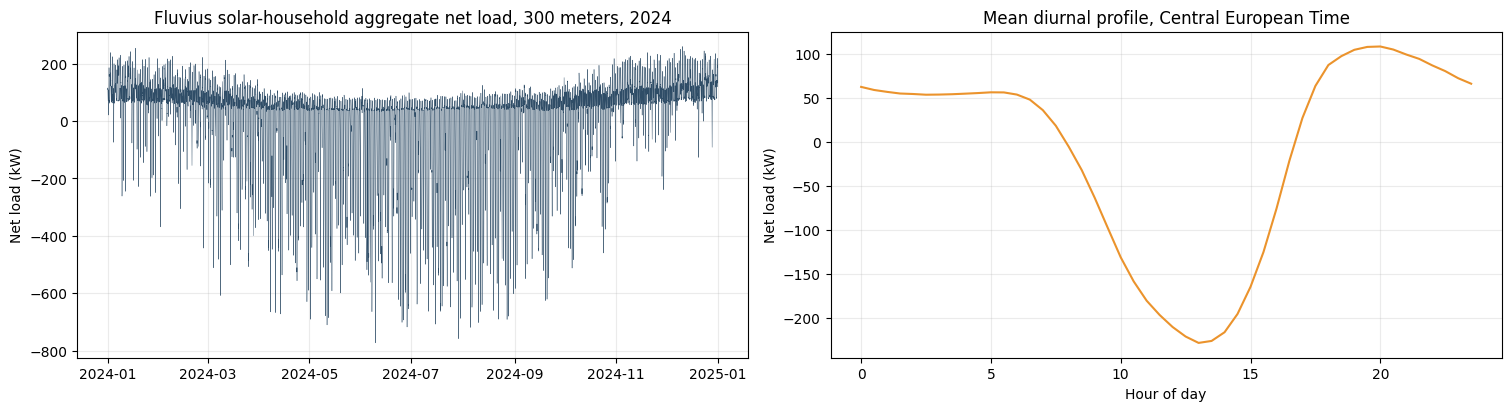

In [4]:
readings["netload_kWh"] = readings["Volume_Afname_KWh"] - readings["Volume_Injectie_KWh"]
quarter_hourly = readings.groupby("datetime")[["Volume_Afname_KWh", "Volume_Injectie_KWh", "netload_kWh"]].sum()
if not quarter_hourly.index.equals(QUARTER_HOUR_INDEX):
    raise AssertionError("Aggregated quarter-hours do not match the expected index")

half_hourly = quarter_hourly.resample("30min").sum()
if not half_hourly.index.equals(EXPECTED_INDEX):
    raise AssertionError("Resampled half-hours do not match the expected index")

ds39 = pd.DataFrame({"datetime": EXPECTED_INDEX, "netload_kW": (half_hourly["netload_kWh"] * 2).values})
ds39.to_csv(DS39_PATH, index=False)

print(f"Exported {DS39_PATH.name}: {ds39.shape[0]:,} rows from {EXPECTED_METERS} meters")
print(f"Mean net load {ds39['netload_kW'].mean():.1f} kW, min {ds39['netload_kW'].min():.1f} kW, max {ds39['netload_kW'].max():.1f} kW")
print(f"Annual offtake {quarter_hourly['Volume_Afname_KWh'].sum() / 1000:.0f} MWh, injection {quarter_hourly['Volume_Injectie_KWh'].sum() / 1000:.0f} MWh")
display(ds39.head())

fig, axes = plt.subplots(1, 2, figsize=(15, 4), constrained_layout=True)
axes[0].plot(ds39["datetime"], ds39["netload_kW"], linewidth=0.3, color="#2F4D67")
axes[0].set_title(f"Fluvius solar-household aggregate net load, {EXPECTED_METERS} meters, 2024")
axes[0].set_ylabel("Net load (kW)")
slot = ds39["datetime"].dt.hour + ds39["datetime"].dt.minute / 60
diurnal = ds39.groupby(slot)["netload_kW"].mean()
axes[1].plot(diurnal.index, diurnal.values, color="#EB932C")
axes[1].set_title("Mean diurnal profile, Central European Time")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Net load (kW)")
for ax in axes:
    ax.grid(alpha=0.25)
plt.show()


## 5. Add Brussels-Uccle weather for `ds40`

Fluvius publishes no location for its meters, so one reference station is used for all of Flanders: Brussels-Uccle, the Royal Meteorological Institute's reference site. Hourly temperature (°C), relative humidity (%) and wind speed (km/h) come from the Open-Meteo historical weather API in UTC, are moved to Central European Time, and are interpolated in time to the half-hourly index. The columns are renamed to the names used by the ASHD and ACAP-EDP datasets so the same model configuration applies.

In [5]:
if not OPEN_METEO_PATH.exists():
    OPEN_METEO_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(OPEN_METEO_URL, OPEN_METEO_PATH)
    print(f"Fetched Open-Meteo archive to {OPEN_METEO_PATH.relative_to(RAW_DATA_ROOT)}")

with open(OPEN_METEO_PATH, encoding="utf-8") as handle:
    open_meteo = json.load(handle)
if open_meteo["hourly_units"] != {"time": "iso8601", "temperature_2m": "°C", "relative_humidity_2m": "%", "wind_speed_10m": "km/h"}:
    raise AssertionError(f"Unexpected Open-Meteo units: {open_meteo['hourly_units']}")

hourly = pd.DataFrame(open_meteo["hourly"])
hourly["datetime"] = pd.to_datetime(hourly["time"]) + pd.Timedelta(hours=1)  # UTC to CET
hourly = hourly.set_index("datetime")[["temperature_2m", "relative_humidity_2m", "wind_speed_10m"]]
hourly.columns = WEATHER_COLUMNS

weather = (
    hourly
    .reindex(hourly.index.union(EXPECTED_INDEX))
    .interpolate(method="time", limit_area="inside")
    .reindex(EXPECTED_INDEX)
)
if weather.isna().any().any():
    raise ValueError(f"Weather is missing values after interpolation:\n{weather.isna().sum()}")

ds40 = ds39.merge(weather.reset_index(), on="datetime", how="left", validate="one_to_one")
ds40 = ds40[["datetime", "netload_kW", *WEATHER_COLUMNS]]
ds40.to_csv(DS40_PATH, index=False)

print(f"Open-Meteo grid point: {open_meteo['latitude']:.3f} N, {open_meteo['longitude']:.3f} E, {open_meteo['elevation']:.0f} m")
print(f"Exported {DS40_PATH.name}: {ds40.shape[0]:,} rows")
display(ds40.describe().round(2))


Open-Meteo grid point: 50.791 N, 4.324 E, 90 m
Exported ds40_fluvius_pv_30min_with_weather.csv: 17,568 rows


,datetime,netload_kW,air_temperature_in_degrees_c,relative_humidity_in_percentage,wind_speed_in_km_h
count,17568,17568.00,17568.00,17568.00,17568.00
mean,2024-07-01 23:45:00,-10.52,11.55,81.22,14.55
min,2024-01-01 00:00:00,-773.33,-6.40,35.00,0.40
25%,2024-04-01 11:52:30,-42.72,7.35,73.00,8.70
50%,2024-07-01 23:45:00,52.94,11.40,84.00,13.50
75%,2024-10-01 11:37:30,84.75,15.95,91.00,19.00
max,2024-12-31 23:30:00,260.07,32.90,100.00,50.30
std,NaN,174.19,6.33,12.38,7.38


## 6. Final validation

Confirm row counts, half-hourly regularity, missing values, column order and the date range for both datasets, then copy them to the publication data folder.

In [6]:
expected_columns = {
    DS39_PATH.name: ["datetime", "netload_kW"],
    DS40_PATH.name: ["datetime", "netload_kW", *WEATHER_COLUMNS],
}

validation_rows = []
for path in [DS39_PATH, DS40_PATH]:
    dataset = pd.read_csv(path, parse_dates=["datetime"])
    if list(dataset.columns) != expected_columns[path.name]:
        raise AssertionError(f"Unexpected columns in {path.name}: {list(dataset.columns)}")
    if dataset.shape[0] != EXPECTED_ROWS:
        raise AssertionError(f"{path.name} expected {EXPECTED_ROWS:,} rows, found {dataset.shape[0]:,}")
    if dataset["datetime"].duplicated().any():
        raise AssertionError(f"{path.name} contains duplicate timestamps")
    if dataset.isna().any().any():
        raise AssertionError(f"{path.name} contains missing values")
    if dataset["datetime"].min() != START or dataset["datetime"].max() != END:
        raise AssertionError(f"{path.name} has an unexpected date range")
    freq_minutes = dataset["datetime"].diff().dropna().dt.total_seconds().unique() / 60
    if len(freq_minutes) != 1 or freq_minutes[0] != 30:
        raise AssertionError(f"{path.name} does not have regular 30-minute spacing")

    shutil.copyfile(path, PUBLICATION_DATA_DIR / path.name)
    validation_rows.append({
        "dataset": path.name,
        "rows": dataset.shape[0],
        "columns": ", ".join(dataset.columns),
        "start": dataset["datetime"].min(),
        "end": dataset["datetime"].max(),
        "missing_values": int(dataset.isna().sum().sum()),
    })

validation = pd.DataFrame(validation_rows)
display(validation)
print("All Fluvius dataset exports passed validation and were copied to the publication data folder.")


,dataset,rows,columns,start,end,missing_values
0,ds39_fluvius_pv_30min.csv,17568,"datetime, netload_kW",2024-01-01,2024-12-31 23:30:00,0
1,ds40_fluvius_pv_30min_with_weather.csv,17568,"datetime, netload_kW, air_temperature_in_degre...",2024-01-01,2024-12-31 23:30:00,0


All Fluvius dataset exports passed validation and were copied to the publication data folder.


## Conclusion

`ds39` and `ds40` hold one calendar year (2024) of half-hourly aggregate net load for the 300 Fluvius solar households, on a regular Central European Time index with no missing values. `ds40` adds Brussels-Uccle temperature, humidity and wind speed under the same column names as the Australian datasets, so the model comparison can run on it unchanged at the one-day horizon.